In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [32]:
df = pd.read_csv("run_120K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000006,0.000002,0.000000,119.9886,120.0,2.0,1.0,0.0
1,-0.000006,0.000002,0.230612,119.9868,120.0,2.0,1.0,0.0
2,-0.000006,0.000002,0.476096,119.9849,120.0,2.0,1.0,0.0
3,-0.000006,0.000002,0.694942,119.9837,120.0,2.0,1.0,0.0
4,-0.000006,0.000002,1.031108,119.9833,120.0,2.0,1.0,0.0


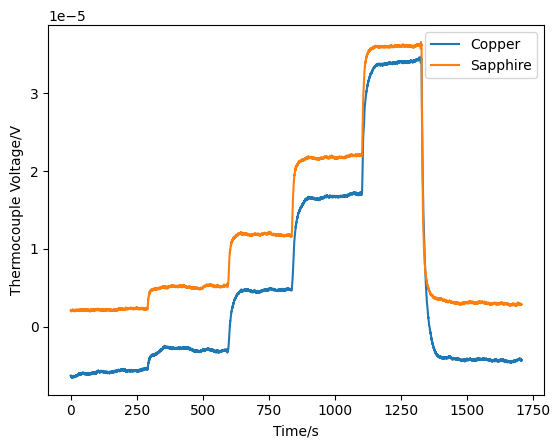

In [33]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [34]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows30K = {
    "V_Copper":   [(0, 115), (200, 292), (340, 430), (500, 670), (725, 855)],
    "V_Sapphire": [(0, 115), (190, 292), (330, 430), (500, 670), (725, 855)],
}

windows40K = {
    "V_Copper":   [(0, 110), (175, 262), (320, 415), (520, 715), (800, 970)],
    "V_Sapphire": [(0, 110), (170, 255), (300, 450), (510, 715), (860, 970)],
}

windows25K = {
    "V_Copper":   [(0, 115), (225, 325), (450, 548), (600, 745), (800, 915)],
    "V_Sapphire": [(0, 115), (215, 330), (375, 550), (600, 745), (800, 915)],
}

windows60K = {
    "V_Copper":   [(0, 120), (180, 345), (400, 615), (700, 955), (1050, 1295), (1340, 1610)],
    "V_Sapphire": [(0, 120), (180, 345), (400, 615), (700, 955), (1050, 1295), (1340, 1610)],
}

windows80K = {
    "V_Copper":   [(0, 215), (300, 635), (700, 1060), (1120, 1400), (1460, 1790), (1870, 2225)],
    "V_Sapphire": [(0, 215), (260, 635), (680, 1060), (1110, 1400), (1460, 1790), (1900, 2090)],
}

windows120K = {
    "V_Copper":   [(25, 280), (350, 590), (650, 825), (900, 1090), (1170, 1315), (1420, 1705)],
    "V_Sapphire": [(25, 280), (350, 590), (650, 825), (900, 1090), (1170, 1315), (1450, 1705)],
}

windows = windows120K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  25-280 s: -5.8033e-06 +- 1.9047e-07 V
  350-590 s: -2.9388e-06 +- 1.8914e-07 V
  650-825 s: 4.6652e-06 +- 1.2880e-07 V
  900-1090 s: 1.6720e-05 +- 2.2605e-07 V
  1170-1315 s: 3.3945e-05 +- 1.7424e-07 V
  1420-1705 s: -4.2722e-06 +- 1.4797e-07 V
V_Sapphire
  25-280 s: 2.1960e-06 +- 9.9925e-08 V
  350-590 s: 5.1290e-06 +- 1.3216e-07 V
  650-825 s: 1.1837e-05 +- 1.0401e-07 V
  900-1090 s: 2.1770e-05 +- 1.4516e-07 V
  1170-1315 s: 3.6041e-05 +- 7.7293e-08 V
  1450-1705 s: 2.9811e-06 +- 1.1292e-07 V


In [35]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)



V_Copper
[0,2.864520268427942e-06,1.046844353252596e-05,2.2523098936939832e-05,3.974810324973093e-05]
[1.904727818300999e-07,1.904727818300999e-07,1.8914310987331396e-07,1.2879955667442343e-07,2.2605076223867443e-07]
V_Sapphire
[0,2.9329355648504195e-06,9.641027074235196e-06,1.957425412342479e-05,3.384531011709233e-05]
[9.992531857402545e-08,9.992531857402545e-08,1.321623583533985e-07,1.0401122972971027e-07,1.4515860734920242e-07]


In [36]:
# --- Baseline-drift correction: straight line between the two baselines ---
v_avg_drift = {}

for material, times in windows.items():
    # midpoint times of every window
    t_mid = [(start + end) / 2 for start, end in times]

    # straight line through (t_first, V_first) and (t_last, V_last)
    t0, t1 = t_mid[0], t_mid[-1]
    v0, v1 = v_avg[material][0], v_avg[material][-1]
    gradient = (v1 - v0) / (t1 - t0)

    def baseline_line(t):
        return v0 + gradient * (t - t0)

    # subtract the line's value at each intermediate step's midpoint
    v_avg_drift[material] = [0]
    for i in range(1, len(times) - 1):
        v_avg_drift[material].append(float(v_avg[material][i] - baseline_line(t_mid[i])))

for material, values in v_avg_drift.items():
    print(material)
    output = "[" + ",".join(f"{v}" for v in values) + "]"
    std_output = "[" + ",".join(f"{v_std[material][i]}" for i in range(len(values))) + "]"
    print(output)
    print(std_output)

V_Copper
[0,2.519759527826877e-06,9.833215081339748e-06,2.1608261381171654e-05,3.8564515195383966e-05]
[1.904727818300999e-07,1.8914310987331396e-07,1.2879955667442343e-07,2.2605076223867443e-07,1.7424230184902764e-07]
V_Sapphire
[0,2.758005571855492e-06,9.318715118638244e-06,1.911006981130439e-05,3.3244763054527064e-05]
[9.992531857402545e-08,1.321623583533985e-07,1.0401122972971027e-07,1.4515860734920242e-07,7.729342803296478e-08]
